EMAIL SPOOFING DETECTION

Dataset Information
Total Records: 36120
Total Columns: 14

Available Columns:
['Popularity Rank', 'Domain', 'Company Name', 'Company Size', 'Year Founded', 'Industry', 'Locality', 'Country', 'TLD', 'SPF', 'DMARC', 'BIMI', 'MTA-STS', 'Posture']

Missing Values:
Popularity Rank     1760
Domain                 0
Company Name           0
Company Size           0
Year Founded       10406
Industry             339
Locality            7329
Country               10
TLD                    0
SPF                    0
DMARC                  0
BIMI                   0
MTA-STS                0
Posture                0
dtype: int64

Email Authentication Results
       Domain SPF DMARC       Risk_Level
   google.com yes   yes Better Protected
microsoft.com yes   yes Better Protected
 facebook.com yes   yes Better Protected
      mail.ru yes    no      Medium Risk
    apple.com yes    no      Medium Risk
instagram.com yes   yes Better Protected
  twitter.com yes   yes Better P

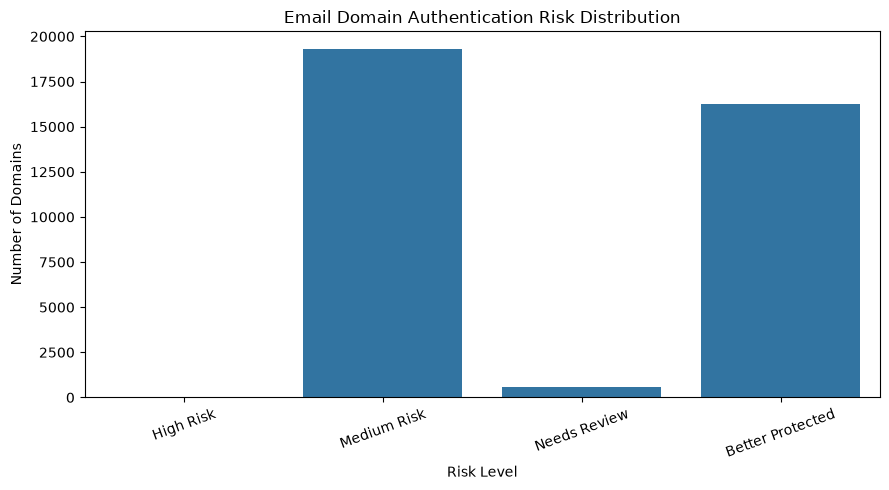


Analysis Completed Successfully!
Results saved as email_spoofing_results.csv


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load dataset
df = pd.read_csv("Email-authentication.csv")

print("EMAIL SPOOFING DETECTION")
print("========================")

# Step 2: Display dataset information
print("\nDataset Information")

print("Total Records:", len(df))

print("Total Columns:", len(df.columns))

print("\nAvailable Columns:")

print(df.columns.tolist())


# Step 3: Check missing values
print("\nMissing Values:")

print(df.isnull().sum())


# Step 4: Clean column names
df.columns = df.columns.str.strip()

# Clean authentication values
for col in ['SPF', 'DMARC', 'BIMI', 'MTA-STS']:
    df[col] = df[col].astype(str).str.lower().str.strip()


# Step 5: Detect authentication risks
def detect_risk(row):

    spf = row['SPF']
    dmarc = row['DMARC']

    if spf == 'no' and dmarc == 'no':

        return "High Risk"

    elif spf == 'yes' and dmarc == 'no':

        return "Medium Risk"

    elif spf == 'no' and dmarc == 'yes':

        return "Needs Review"

    else:

        return "Better Protected"


# Step 6: Apply detection
df['Risk_Level'] = df.apply(detect_risk, axis=1)


# Step 7: Display results
print("\nEmail Authentication Results")

print(
    df[
        ['Domain', 'SPF', 'DMARC', 'Risk_Level']
    ].head(15).to_string(index=False)
)


# Step 8: Calculate risk distribution
print("\nRisk Distribution")

risk_counts = df['Risk_Level'].value_counts()

print(risk_counts)


# Step 9: Calculate SPF and DMARC statistics
print("\nSPF Authentication Statistics")

print(df['SPF'].value_counts())

print("\nDMARC Authentication Statistics")

print(df['DMARC'].value_counts())


# Step 10: Visualize risk distribution
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Risk_Level',
    order=[
        'High Risk',
        'Medium Risk',
        'Needs Review',
        'Better Protected'
    ]
)

plt.title("Email Domain Authentication Risk Distribution")

plt.xlabel("Risk Level")

plt.ylabel("Number of Domains")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()


# Step 11: Save results
df.to_csv(
    "email_spoofing_results.csv",
    index=False
)

print("\nAnalysis Completed Successfully!")

print("Results saved as email_spoofing_results.csv")